# Hito 1 – Exploración inicial de datos COVID-19

**Curso:** Gestión de Datos – IN1232C – Proyecto semestral – Sala de crisis  
**Período:** 22 de enero al 30 de junio de 2020 – **Fuente:** reportes diarios históricos de Johns Hopkins CSSE.

Este notebook cumple las seis tareas del punto de partida del enunciado y la presentación: inspección de `01-22-2020.csv`, explicar nulos, estandarizar nombres y fecha de actualización, consolidar los reportes del período, analizar el top 10 y Chile, y generar un perfilado automático con tres observaciones.

> Los acumulados publicados no son casos diarios. La fecha de cada observación se toma del nombre del archivo, no de `Last Update`.

## Preparación de archivos de entrada

El notebook reutiliza los CSV existentes y descarga únicamente los reportes faltantes del período requerido (161 días, inclusivo). Los datos crudos se mantienen en `data/raw/` y no se versionan.

In [1]:
from datetime import date, datetime
from pathlib import Path
import re
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Encuentra la raíz del proyecto tanto si Jupyter se abrió desde la raíz como desde notebooks/.
raices = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
ROOT = next((p for p in raices if (p / "src").is_dir() and (p / "notebooks").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Abre Jupyter desde la carpeta Proyecto o desde Proyecto/notebooks.")

sys.path.insert(0, str(ROOT / "src"))
from descargar_reportes import descargar_reportes

FECHA_INICIO = date(2020, 1, 22)
FECHA_FIN = date(2020, 6, 30)
RAW_DIR = ROOT / "data" / "raw" / "daily_reports"
REPORTS_DIR = ROOT / "reports"

nuevos = descargar_reportes(FECHA_INICIO, FECHA_FIN, RAW_DIR)
archivos_periodo = []
for archivo in RAW_DIR.glob("*.csv"):
    try:
        fecha_archivo = datetime.strptime(archivo.stem, "%m-%d-%Y").date()
    except ValueError:
        continue
    if FECHA_INICIO <= fecha_archivo <= FECHA_FIN:
        archivos_periodo.append((fecha_archivo, archivo))
archivos_periodo.sort(key=lambda elemento: elemento[0])

esperados = (FECHA_FIN - FECHA_INICIO).days + 1
if len(archivos_periodo) != esperados:
    raise FileNotFoundError(
        f"Se esperaban {esperados} reportes diarios; se encontraron {len(archivos_periodo)} en {RAW_DIR}."
    )
print(f"Reportes nuevos descargados: {nuevos}; reportes del Hito 1 disponibles: {len(archivos_periodo)}")
print(f"Período: {archivos_periodo[0][1].name} a {archivos_periodo[-1][1].name}")

Reportes nuevos descargados: 0; reportes del Hito 1 disponibles: 161
Período: 01-22-2020.csv a 06-30-2020.csv


## 1. Inspección del primer reporte

Se revisan las primeras filas, dimensiones, tipos y nulos de `01-22-2020.csv`. Un campo geográfico vacío puede representar un registro nacional; un conteo nulo significa que la fuente no publicó ese valor y **no** debe convertirse automáticamente en cero.

In [2]:
primer_archivo = RAW_DIR / "01-22-2020.csv"
primer_dia = pd.read_csv(primer_archivo)

NOMBRES_MOSTRAR = {
    "Province/State": "Provincia/Estado",
    "Country/Region": "País/Región",
    "Last Update": "Última actualización",
    "Confirmed": "Confirmados",
    "Deaths": "Fallecidos",
    "Recovered": "Recuperados",
}

display(primer_dia.head().rename(columns=NOMBRES_MOSTRAR))
print(f"Dimensiones: {primer_dia.shape[0]:,} filas por {primer_dia.shape[1]} columnas")
display(primer_dia.dtypes.rename("tipo").rename(index=NOMBRES_MOSTRAR).to_frame())

nulos_primer_dia = pd.DataFrame({
    "nulos": primer_dia.isna().sum(),
    "porcentaje": (primer_dia.isna().mean() * 100).round(1),
}).rename(index=NOMBRES_MOSTRAR).sort_values("nulos", ascending=False)
display(nulos_primer_dia)

,Provincia/Estado,País/Región,Última actualización,Confirmados,Fallecidos,Recuperados
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN


Dimensiones: 76 filas por 6 columnas


,tipo
Provincia/Estado,object
País/Región,object
Última actualización,object
Confirmados,float64
Fallecidos,float64
Recuperados,float64


,nulos,porcentaje
Fallecidos,37,48.7
Recuperados,37,48.7
Provincia/Estado,12,15.8
Confirmados,10,13.2
País/Región,0,0.0
Última actualización,0,0.0


### ¿Cómo interpretar los nulos del primer día

- `Province/State` vacío suele indicar que el reporte está a nivel país y no que falte un país.
- `Confirmed`, `Deaths` o `Recovered` nulos indican que ese reporte no entregó el conteo; no se imputan como cero.
- La ausencia de una columna en ciertos reportes refleja cambios de esquema; al concatenar, pandas la crea y deja `NaN` en las fechas donde aún no existía.

## 2. Estandarización y consolidación enero – junio

Se normalizan nombres equivalentes de los distintos esquemas a `snake_case` y se conserva la fecha de actualización como `AAAA-MM-DD`. `report_date` se deriva del nombre del CSV. La concatenación alinea columnas y conserva nulos donde un campo no estaba disponible.

In [3]:
ALIAS_COLUMNAS = {
    "latitude": "lat",
    "longitude": "long",
    "long_": "long",
    "incidence_rate": "incident_rate",
}

def estandarizar(df: pd.DataFrame) -> pd.DataFrame:
    """Normaliza nombres de columnas y fechas de actualización de JHU."""
    df = df.copy()
    normalizadas = {}
    for nombre in df.columns:
        snake = re.sub(r"[^0-9a-zA-Z]+", "_", nombre.strip()).strip("_").lower()
        normalizadas[nombre] = ALIAS_COLUMNAS.get(snake, snake)
    df = df.rename(columns=normalizadas)
    if "last_update" in df.columns:
        actualizado = pd.to_datetime(
            df["last_update"], format="mixed", errors="coerce", utc=True
        )
        df["last_update"] = actualizado.dt.strftime("%Y-%m-%d")
    return df

frames = []
firmas_esquema = {}
for fecha_archivo, archivo in archivos_periodo:
    diario_original = pd.read_csv(archivo)
    firma = tuple(diario_original.columns)
    firmas_esquema.setdefault(firma, {"reportes": 0, "primera_fecha": fecha_archivo, "ultima_fecha": fecha_archivo})
    firmas_esquema[firma]["reportes"] += 1
    firmas_esquema[firma]["ultima_fecha"] = fecha_archivo

    diario = estandarizar(diario_original)
    diario["report_date"] = pd.Timestamp(fecha_archivo)
    frames.append(diario)

reportes = pd.concat(frames, ignore_index=True, sort=False)
print(f"Consolidado: {len(reportes):,} filas  x  {len(reportes.columns)} columnas; {reportes['report_date'].nunique()} fechas")
print("Columnas estandarizadas:", ", ".join(reportes.columns))

resumen_esquemas = pd.DataFrame(
    [{"reportes": v["reportes"], "desde": v["primera_fecha"], "hasta": v["ultima_fecha"]}
     for v in firmas_esquema.values()]
).sort_values("desde", ignore_index=True)
print(f"Esquemas originales distintos en el período: {len(resumen_esquemas)}")
display(resumen_esquemas)
display(reportes.head())

Consolidado: 350,945 filas  x  15 columnas; 161 fechas
Columnas estandarizadas: province_state, country_region, last_update, confirmed, deaths, recovered, report_date, lat, long, fips, admin2, active, combined_key, incident_rate, case_fatality_ratio
Esquemas originales distintos en el período: 4


,reportes,desde,hasta
0,39,2020-01-22,2020-02-29
1,21,2020-03-01,2020-03-21
2,68,2020-03-22,2020-05-28
3,33,2020-05-29,2020-06-30


,province_state,country_region,last_update,confirmed,deaths,recovered,report_date,lat,long,fips,admin2,active,combined_key,incident_rate,case_fatality_ratio
0,Anhui,Mainland China,2020-01-22,1.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Beijing,Mainland China,2020-01-22,14.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Chongqing,Mainland China,2020-01-22,6.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fujian,Mainland China,2020-01-22,1.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gansu,Mainland China,2020-01-22,NaN,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Top 10 al 30 de junio y evolución de Chile

`confirmed` es acumulado. Para cada país y fecha se usa el registro nacional cuando existe; solo cuando no existe se suman los registros subnacionales. Esta regla evita contar dos veces países que publican ambos niveles. En la serie chilena, el registro pasa de nacional a regional durante mayo de 2020.

,Casos confirmados acumulados
País/Región,
US,"2,653,658"
Brazil,"1,412,669"
Russia,"646,929"
India,"585,493"
United Kingdom,"314,157"
Peru,"285,213"
Chile,"279,393"
Spain,"249,271"
Italy,"240,578"


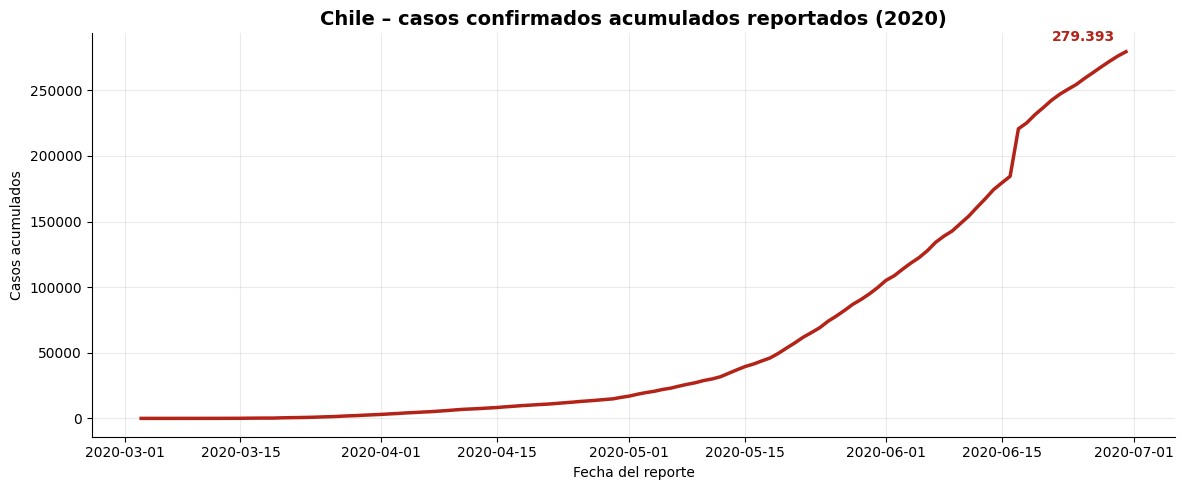

In [4]:
# Marca filas geográficas; un registro sin provincia ni condado es nacional.
columnas_geograficas = [c for c in ("province_state", "admin2") if c in reportes.columns]
if not columnas_geograficas:
    raise KeyError("No se encontraron columnas geográficas para distinguir niveles de reporte.")
es_subnacional = reportes[columnas_geograficas].notna().any(axis=1)
claves = ["report_date", "country_region"]

totales_nacionales = (
    reportes.loc[~es_subnacional]
    .groupby(claves)["confirmed"]
    .max()
)
totales_subnacionales = (
    reportes.loc[es_subnacional]
    .groupby(claves)["confirmed"]
    .sum(min_count=1)
)
totales_pais_fecha = totales_nacionales.combine_first(totales_subnacionales).rename("confirmed")

fecha_corte = pd.Timestamp("2020-06-30")
if fecha_corte not in totales_pais_fecha.index.get_level_values("report_date"):
    raise ValueError("El consolidado no contiene el corte 2020-06-30.")
top10 = (
    totales_pais_fecha.xs(fecha_corte, level="report_date")
    .dropna()
    .sort_values(ascending=False)
    .head(10)
    .rename("casos_confirmados_acumulados")
    .to_frame()
)
top10_mostrar = top10.rename_axis("País/Región").rename(columns={"casos_confirmados_acumulados": "Casos confirmados acumulados"})
display(top10_mostrar.style.format("{:,.0f}"))

serie_chile = (
    totales_pais_fecha.xs("Chile", level="country_region")
    .dropna()
    .sort_index()
)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(serie_chile.index, serie_chile.values, color="#b42318", linewidth=2.5)
ax.set_title("Chile – casos confirmados acumulados reportados (2020)", fontsize=14, weight="bold")
ax.set_xlabel("Fecha del reporte")
ax.set_ylabel("Casos acumulados")
ax.grid(True, alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.annotate(
    f"{serie_chile.iloc[-1]:,.0f}".replace(",", "."),
    xy=(serie_chile.index[-1], serie_chile.iloc[-1]),
    xytext=(-8, 8), textcoords="offset points", ha="right", color="#b42318", weight="bold"
)
fig.tight_layout()
plt.show()

## 4. Perfilado automático y tres observaciones

El perfilado se genera como HTML en `reports/perfil_enero_junio_2020.html`. Las observaciones de abajo se calculan desde el subconjunto exacto del Hito 1 y resumen lo que conviene explicar en la presentación.

In [5]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*")
warnings.filterwarnings("ignore", message=".*ydata_profiling.*deprecated.*", category=DeprecationWarning)
from ydata_profiling import ProfileReport

import sys
for flujo in (sys.stdout, sys.stderr):
    if hasattr(flujo, "reconfigure"):
        flujo.reconfigure(encoding="utf-8")

REPORTS_DIR.mkdir(exist_ok=True)
perfil = ProfileReport(
    reportes,
    title="Perfil exploratorio COVID-19 – 22 ene a 30 jun 2020",
    minimal=True,
    progress_bar=False,
)
perfil_path = REPORTS_DIR / "perfil_enero_junio_2020.html"
perfil.to_file(perfil_path)
print(f"Perfil HTML generado: {perfil_path}")

C:\Users\hecto\AppData\Local\Temp\ipykernel_20768\3684051237.py:4: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


  0%|          | 0/15 [00:00<?, ?it/s]

  7%|▋         | 1/15 [00:00<00:09,  1.46it/s]

 27%|██▋       | 4/15 [00:00<00:02,  5.47it/s]

100%|██████████| 15/15 [00:00<00:00, 16.92it/s]

Perfil HTML generado: C:\Users\hecto\OneDrive\Escritorio\u\gestion de datos\Proyecto\reports\perfil_enero_junio_2020.html


In [6]:
# Hechos calculados para presentar; las cifras se derivan de los reportes cargados.
filas_por_fecha = reportes.groupby("report_date").size()
porcentaje_nulos = reportes.isna().mean().mul(100)
chile_filas = reportes.loc[reportes["country_region"].eq("Chile")].groupby("report_date").size()
cambio_nivel_chile = chile_filas[chile_filas.ne(chile_filas.shift())]

print()
print("OBSERVACIÓN 1 – Primer reporte")
print(
    f"El 22-ene-2020 hay {len(primer_dia)} filas y {primer_dia.shape[1]} columnas. "
    f"Nulos destacados: Province/State={primer_dia['Province/State'].isna().sum()}, "
    f"Confirmed={primer_dia['Confirmed'].isna().sum()}, "
    f"Deaths={primer_dia['Deaths'].isna().sum()}, "
    f"Recovered={primer_dia['Recovered'].isna().sum()}."
)
print("Lectura: un nulo geográfico puede representar un total nacional; los nulos de conteos no equivalen a cero.")

print()
print("OBSERVACIÓN 2 – Esquema y completitud")
print(
    f"Se consolidaron {len(reportes):,} filas en {reportes['report_date'].nunique()} días "
    f"y {len(firmas_esquema)} esquemas originales. Los reportes diarios varían entre "
    f"{filas_por_fecha.min():,} y {filas_por_fecha.max():,} filas."
)
for columna in ("incident_rate", "case_fatality_ratio"):
    if columna in porcentaje_nulos.index:
        print(f"{columna}: {porcentaje_nulos[columna]:.1f}% nulo; la columna aparece en una etapa posterior, no se imputa.")

print()
print("OBSERVACIÓN 3 – Cambio de granularidad en Chile")
if not cambio_nivel_chile.empty:
    fecha_cambio = cambio_nivel_chile.index[-1]
    print(
        f"Chile pasa de {int(chile_filas.iloc[0])} registro(s) el {chile_filas.index[0]:%d-%b-%Y} "
        f"a {int(chile_filas.loc[fecha_cambio])} registros el {fecha_cambio:%d-%b-%Y}. "
        f"Al 30-jun-2020 suma {serie_chile.loc[pd.Timestamp('2020-06-30')]:,.0f} casos acumulados "
        "con la regla anti doble conteo."
    )
print("Lectura: el cambio de país a regiones exige respetar el nivel geográfico al comparar fechas.")



OBSERVACIÓN 1 – Primer reporte
El 22-ene-2020 hay 76 filas y 6 columnas. Nulos destacados: Province/State=12, Confirmed=10, Deaths=37, Recovered=37.
Lectura: un nulo geográfico puede representar un total nacional; los nulos de conteos no equivalen a cero.

OBSERVACIÓN 2 – Esquema y completitud
Se consolidaron 350,945 filas en 161 días y 4 esquemas originales. Los reportes diarios varían entre 76 y 3,824 filas.
incident_rate: 65.5% nulo; la columna aparece en una etapa posterior, no se imputa.
case_fatality_ratio: 65.4% nulo; la columna aparece en una etapa posterior, no se imputa.

OBSERVACIÓN 3 – Cambio de granularidad en Chile
Chile pasa de 1 registro(s) el 03-Mar-2020 a 17 registros el 20-May-2020. Al 30-jun-2020 suma 279,393 casos acumulados con la regla anti doble conteo.
Lectura: el cambio de país a regiones exige respetar el nivel geográfico al comparar fechas.


## Propuesta P7 – fuente externa

**Pregunta propuesta:** ¿Cómo se relaciona la cobertura de vacunación con la mortalidad reportada en las ocho semanas siguientes en Chile, Perú, Estados Unidos y Brasil?

**Fuente:** Our World in Data – vacunación, cruzada con JHU por código ISO3. La pregunta se responde con el período completo de la pandemia en una etapa posterior; los datos de enero – junio de 2020 de este Hito preceden a la vacunación masiva. El análisis será una asociación ecológica descriptiva, no una conclusión causal.

## Cierre para la exposición

1. El primer reporte ya muestra datos incompletos; los nulos deben interpretarse según el campo, no reemplazarse automáticamente.
2. La estructura y el número de filas cambian a medida que JHU incorpora más detalle; la consolidación conserva esos cambios sin inventar cifras.
3. Chile cambia de reporte nacional a regional en mayo, por lo que la serie se construye sin mezclar ni duplicar niveles geográficos.

**Artefacto de perfilado:** `reports/perfil_enero_junio_2020.html`.